# Barcelona vs PSG – Recent Form Analysis
Barça (LaLiga) and PSG (Ligue 1) across **2025/26** and **2026/27 (so far)**.

Colours used throughout: 🔵 Barcelona, 🟠 PSG.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-whitegrid")
P="/mnt/user-data/uploads/"   # change if running locally
FILES={"Barcelona":{"2025/26":"laliga_25_26.csv","2026/27":"laliga_26_27.csv"},
       "Paris SG":{"2025/26":"F1__1_.csv","2026/27":"F1.csv"}}
COL={"Barcelona":"#1f4e9c","Paris SG":"#e8741e"}

def prep(path, team, season):
    d=pd.read_csv(P+path, encoding="utf-8-sig")
    d["Date"]=pd.to_datetime(d["Date"], dayfirst=True)
    d=d[(d.HomeTeam==team)|(d.AwayTeam==team)].sort_values("Date").copy()
    h=d.HomeTeam==team
    d["Venue"]=h.map({True:"Home",False:"Away"})
    d["Opponent"]=d.AwayTeam.where(h,d.HomeTeam)
    d["GF"]=d.FTHG.where(h,d.FTAG); d["GA"]=d.FTAG.where(h,d.FTHG)
    d["Shots"]=d.HS.where(h,d["AS"]); d["SoT"]=d.HST.where(h,d.AST)
    if "HxG" in d: d["xG"]=d.HxG.where(h,d.AxG); d["xGA"]=d.AxG.where(h,d.HxG)
    d["Result"]=(d.GF>d.GA).map({True:"W"}).fillna((d.GF==d.GA).map({True:"D"})).fillna("L")
    d["Pts"]=d.Result.map({"W":3,"D":1,"L":0})
    d["Team"]=team; d["Season"]=season
    d["Match"]=range(1,len(d)+1); d["CumPts"]=d.Pts.cumsum()
    return d

data={(t,s):prep(f,t,s) for t,fs in FILES.items() for s,f in fs.items()}
df=pd.concat(data.values(),ignore_index=True)
print(df.groupby(["Team","Season"]).size().unstack().rename_axis(None).to_string())

Season     2025/26  2026/27
Barcelona       38        8
Paris SG        34        6


## 1. Season summary
Per-game numbers so the different match counts are comparable.

In [2]:
def summ(d):
    return pd.Series({"Played":len(d),"Pts/G":d.Pts.mean(),"Win %":(d.Result=="W").mean()*100,
      "Goals For/G":d.GF.mean(),"Goals Against/G":d.GA.mean(),"Goal Diff/G":(d.GF-d.GA).mean(),
      "Shots/G":d.Shots.mean(),"SoT/G":d.SoT.mean(),"Clean Sheet %":(d.GA==0).mean()*100}).round(2)
s=df.groupby(["Season","Team"]).apply(summ,include_groups=False).T
s

Season            2025/26            2026/27         
Team            Barcelona Paris SG Barcelona Paris SG
Played              38.00    34.00      8.00     6.00
Pts/G                2.47     2.24      3.00     1.83
Win %               81.58    70.59    100.00    50.00
Goals For/G          2.50     2.18      4.25     1.83
Goals Against/G      0.95     0.85      0.88     1.33
Goal Diff/G          1.55     1.32      3.38     0.50
Shots/G             18.21    17.71     21.62    21.33
SoT/G                6.76     6.68      8.25     7.33
Clean Sheet %       39.47    52.94     50.00    16.67

## 2. Points race
Cumulative points by match number.

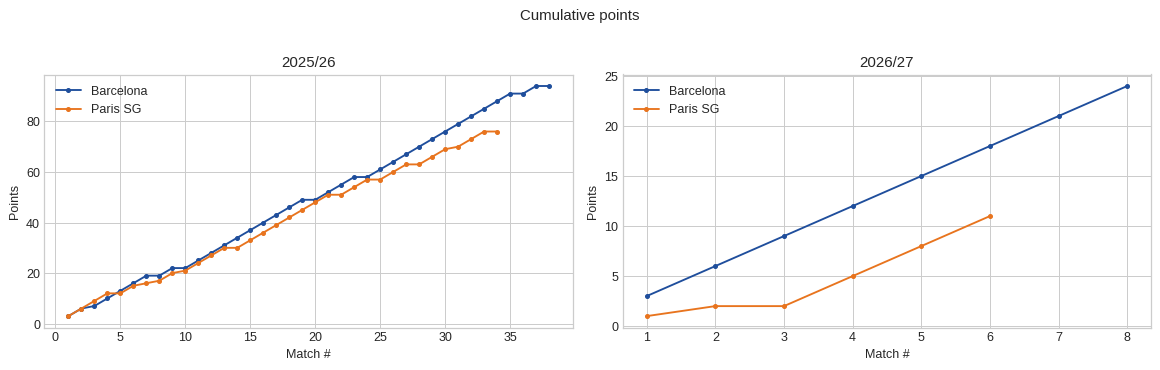

In [3]:
fig,ax=plt.subplots(1,2,figsize=(13,4),sharey=False)
for a,sea in zip(ax,["2025/26","2026/27"]):
    for t in COL:
        d=data[(t,sea)]; a.plot(d.Match,d.CumPts,marker="o",ms=3,color=COL[t],label=t)
    a.set(title=sea,xlabel="Match #",ylabel="Points"); a.legend()
plt.suptitle("Cumulative points",y=1.02); plt.tight_layout(); plt.show()

## 3. Results and goals

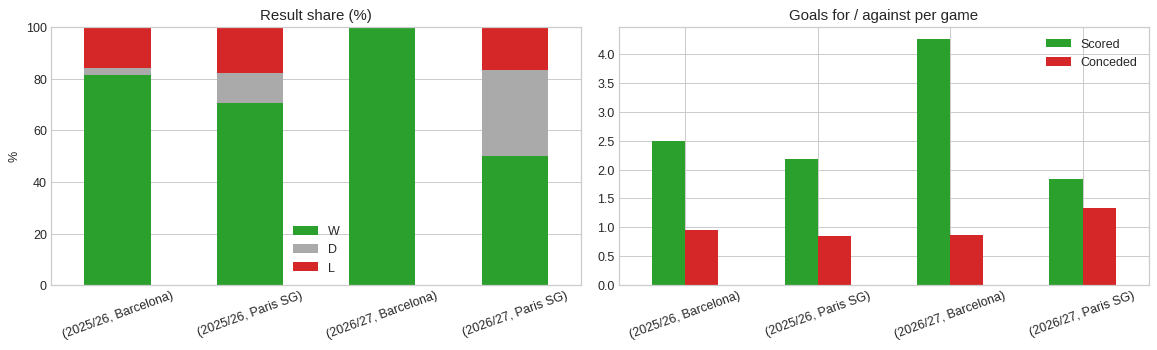

In [4]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
r=(df.groupby(["Season","Team"]).Result.value_counts(normalize=True).unstack().reindex(columns=["W","D","L"]).fillna(0)*100)
r.plot.bar(stacked=True,ax=ax[0],color=["#2ca02c","#aaaaaa","#d62728"],rot=20)
ax[0].set(title="Result share (%)",xlabel="",ylabel="%"); ax[0].legend(title="")
g=df.groupby(["Season","Team"])[["GF","GA"]].mean()
g.plot.bar(ax=ax[1],color=["#2ca02c","#d62728"],rot=20)
ax[1].set(title="Goals for / against per game",xlabel=""); ax[1].legend(["Scored","Conceded"])
plt.tight_layout(); plt.show()

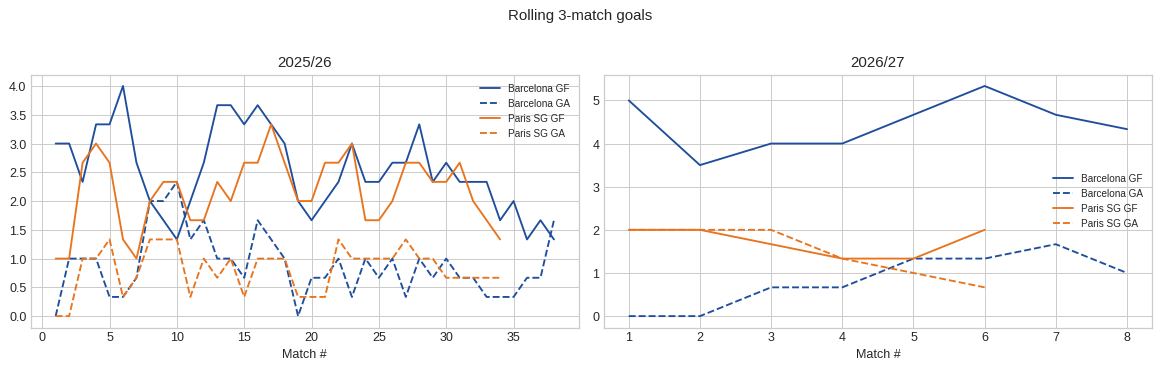

In [5]:
# 3-match rolling goals for (solid) and against (dashed)
fig,ax=plt.subplots(1,2,figsize=(13,4))
for a,sea in zip(ax,["2025/26","2026/27"]):
    for t in COL:
        d=data[(t,sea)]
        a.plot(d.Match,d.GF.rolling(3,min_periods=1).mean(),color=COL[t],label=t+" GF")
        a.plot(d.Match,d.GA.rolling(3,min_periods=1).mean(),"--",color=COL[t],label=t+" GA")
    a.set(title=sea,xlabel="Match #"); a.legend(fontsize=8)
plt.suptitle("Rolling 3-match goals",y=1.02); plt.tight_layout(); plt.show()

## 4. Attack quality: shots and shots on target

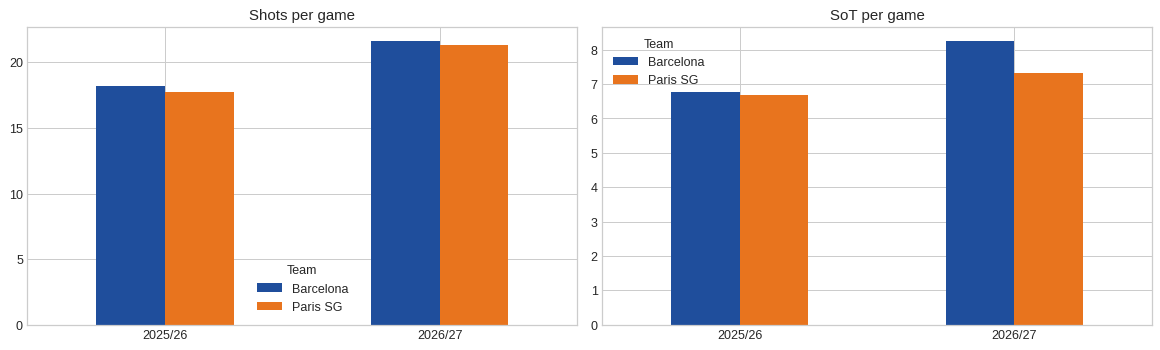

SoT %  Goals per shot %
Season  Team                              
2025/26 Barcelona   37.1              13.7
        Paris SG    37.7              12.3
2026/27 Barcelona   38.2              19.7
        Paris SG    34.4               8.6

In [6]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
for a,m in zip(ax,["Shots","SoT"]):
    df.groupby(["Season","Team"])[m].mean().unstack().plot.bar(ax=a,color=[COL[t] for t in ["Barcelona","Paris SG"]],rot=0)
    a.set(title=f"{m} per game",xlabel="")
plt.tight_layout(); plt.show()
# shot accuracy & conversion
q=df.groupby(["Season","Team"]).apply(lambda d:pd.Series({"SoT %":d.SoT.sum()/d.Shots.sum()*100,"Goals per shot %":d.GF.sum()/d.Shots.sum()*100}),include_groups=False).round(1)
q

## 5. Home vs away

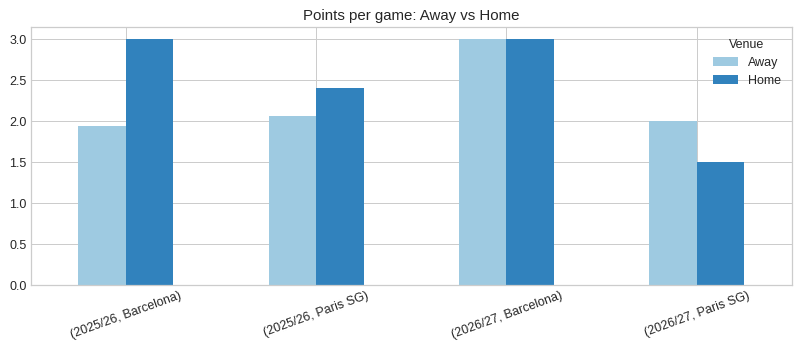

Venue              Away  Home
Season  Team                 
2025/26 Barcelona  1.95  3.00
        Paris SG   2.06  2.41
2026/27 Barcelona  3.00  3.00
        Paris SG   2.00  1.50

In [7]:
h=df.groupby(["Season","Team","Venue"]).Pts.mean().unstack()
h.plot.bar(figsize=(9,4),color=["#9ecae1","#3182bd"],rot=20,title="Points per game: Away vs Home")
plt.xlabel(""); plt.tight_layout(); plt.show()
h.round(2)

## 6. xG vs actual goals (2026/27 only)
xG is only in the 2026/27 files.

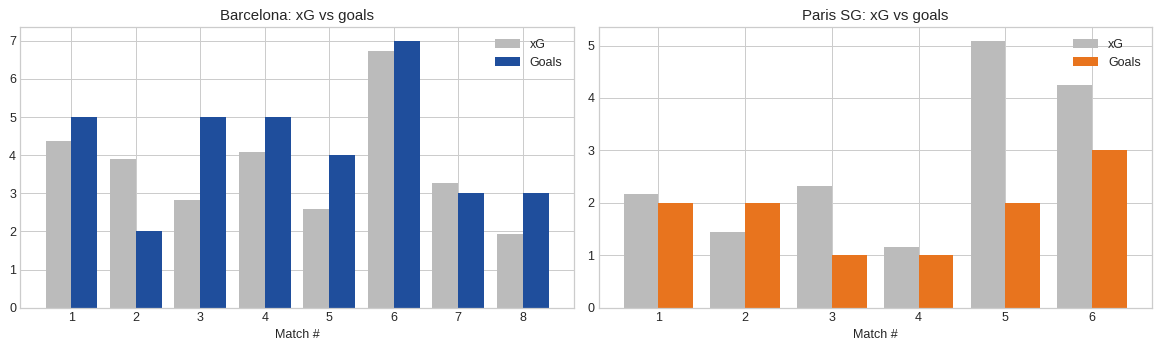

,xG,GF,xGA,GA
Barcelona,3.72,4.25,0.96,0.88
Paris SG,2.74,1.83,1.22,1.33


In [8]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
for a,t in zip(ax,COL):
    d=data[(t,"2026/27")]; x=range(len(d)); w=0.4
    a.bar([i-w/2 for i in x],d.xG,w,label="xG",color="#bbbbbb")
    a.bar([i+w/2 for i in x],d.GF,w,label="Goals",color=COL[t])
    a.set(title=f"{t}: xG vs goals",xlabel="Match #",xticks=list(x),xticklabels=d.Match); a.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({t:data[(t,"2026/27")][["xG","GF","xGA","GA"]].mean() for t in COL}).round(2).T

## 7. Current form snapshot (2026/27)

In [9]:
rows=[]
for t in COL:
    d=data[(t,"2026/27")]; l=d.tail(5)
    print(f"{t:10s} last {len(l)}:", " ".join(l.Result))
    rows.append({"Team":t,"Last-5 Pts":l.Pts.sum(),"Last-5 GF":l.GF.sum(),"Last-5 GA":l.GA.sum(),"Unbeaten run":(d.Result[::-1]!="L").cumprod().sum()})
pd.DataFrame(rows).set_index("Team")

Barcelona  last 5: W W W W W
Paris SG   last 5: D L W W W


,Last-5 Pts,Last-5 GF,Last-5 GA,Unbeaten run
Team,,,,
Barcelona,15,22,5,8
Paris SG,10,9,6,3


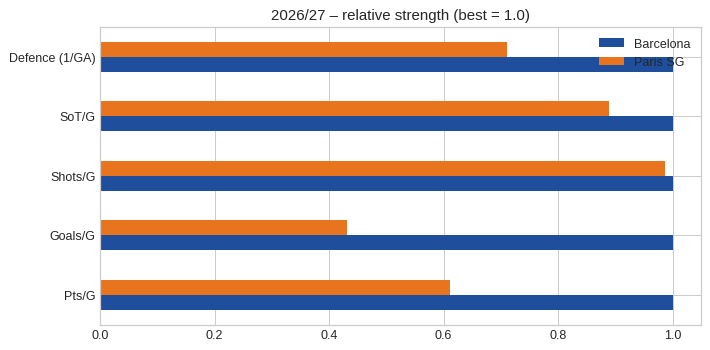

In [10]:
# normalised comparison on 2026/27 per-game metrics (higher = better)
m=pd.DataFrame({t:{"Pts/G":data[(t,"2026/27")].Pts.mean(),"Goals/G":data[(t,"2026/27")].GF.mean(),
    "Shots/G":data[(t,"2026/27")].Shots.mean(),"SoT/G":data[(t,"2026/27")].SoT.mean(),
    "Defence (1/GA)":1/(data[(t,"2026/27")].GA.mean()+0.25)} for t in COL})
(m.div(m.max(axis=1),axis=0)).plot.barh(figsize=(8,4),color=[COL[t] for t in COL],title="2026/27 – relative strength (best = 1.0)")
plt.tight_layout(); plt.show()

## Conclusion

- **2025/26:** Barça had the better points per game (2.47 vs 2.24) and scored more (2.50 vs 2.18 per game). PSG conceded slightly less (0.85 vs 0.95) and kept more clean sheets (53% vs 39%). Their record away from home was better than Barça's (2.06 vs 1.95 points per game).
- **2026/27 so far:** Barça are perfect after 8 games, scoring 4.25 goals per game, with 3.72 xG per game behind that. PSG have 1.83 points per game after 6, scoring 1.83 per game from 2.74 xG, so they are under-finishing. They are also conceding more than last season (1.33 per game).
- **Form:** Barça are on five straight wins. PSG are unbeaten in 3 after a draw and a loss earlier in the run.
- **Caveats:** Samples are small (8 and 6 matches), the leagues differ in strength, and none of this accounts for opponent quality or Champions League workload.
